# Integrative Assay Summary

In [1]:
import sys
import polars as pl
import pandas as pd
import numpy as np
# Create heatmap with custom colors
from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedFormatter, FixedLocator
import matplotlib as mpl
from matplotlib.patches import Patch
import matplotlib.font_manager as fm
from scipy.stats import fisher_exact, mannwhitneyu
from matplotlib.gridspec import GridSpec
from statannotations.Annotator import Annotator

# Force TrueType font embedding (Type 42)
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

font_path = "../../1_allele_collection/4_manuscript_figures/ARIAL.TTF"
fm.fontManager.addfont(font_path)

font_prop = fm.FontProperties(fname=font_path)
# Set font family to one of the accepted fonts
plt.rcParams.update({
    "font.family": font_prop.get_name(),
    "font.sans-serif": ["ARIAL"],
    "font.size": 12,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
})

# Verify settings
# print(f"pdf.fonttype: {mpl.rcParams['pdf.fonttype']}")
# print(f"ps.fonttype: {mpl.rcParams['ps.fonttype']}")
# print(f"font.family: {mpl.rcParams['font.family']}")

sys.path.append("../../1_allele_collection/2_analysis")
from plot_utils import *
sys.path.append("../../2_individual_assay_results")
from analyses_plot_utils import *

## 1. Loading data

### 1.1 Merge allele collection with DUAL-IPA, Imaging and PPI assays

In [42]:
dualipa_outputs = "../../2_individual_assay_results/dual_ipa/3_outputs"
imaging_outputs = "../../2_individual_assay_results/imaging/3_outputs"
ppi_outputs = "../../2_individual_assay_results/ppi/3_outputs/sqY2H"

allele_col_df = pl.read_csv(f"../../1_allele_collection/3_outputs/VarChAMP_Allele_Collection_1Perc_ClinVar_dbNSFP_pLDDT_RSA_G2P_OMIM_MOI_SpliceAI.tsv", 
                            separator="\t", infer_schema_length=100000).with_columns(
                                pl.col("clinvar_clnsig_clean").replace("6_No_ClinVar", "5_Others")
                            )
                            
dualipa = pl.read_csv(f"{dualipa_outputs}/annotated_perturbation_scores.csv", infer_schema_length=100000).with_columns(
    pl.when(pl.col("dualipa_abun_change")=="Y")
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("dualipa_hit")
)
print("DUAL-IPA:", dualipa.shape[0], dualipa.unique(subset="gene_variant").shape[0])

imaging = pl.read_csv(
    f"{imaging_outputs}/0_imaging_phenotype_summary_clinvar.tsv", separator="\t", infer_schema_length=100000
).rename(
    {
        "U2OS_cc_t_stat": "img_U2OS_cc_t_stat",
        "U2OS_cc_t_pval": "img_U2OS_cc_t_pval",
        "U2OS_cc_t_pval_fdr_bh_adj": "img_U2OS_cc_t_adj_pval",
        "U2OS_prot_abun_t_stat": "img_U2OS_prot_abun_t_stat",
        "U2OS_prot_abun_t_pval": "img_U2OS_prot_abun_t_pval",
        "U2OS_prot_abun_t_pval_fdr_bh_adj": "img_U2OS_prot_abun_t_adj_pval",
        "Metadata_Bio_Batch": "img_Metadata_Bio_Batch"
    }
).with_columns(
    pl.when(pl.col("img_pheno_hit"))
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("imaging_hit")
)
print("Imaging:", imaging.shape[0], imaging.unique(subset="gene_variant").shape[0])

ppi = pl.read_csv(f"{ppi_outputs}/orf_distances_enhanced_metrics.csv", infer_schema_length=100000)
ppi = ppi.rename(
    {
        "db_orf_id": "orf_id", "db_mut_id": "mut_id", 
        "euclid_distance": "ppi_euclid_distance",
        "num_edges": "ppi_num_edges",
        "normalized_euclid_distance_normalized": "ppi_normalized_euclid_distance_normalized"
    }
).with_columns(
    pl.when(pl.col("ppi_normalized_euclid_distance_normalized")>=0.65)
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("ppi_hit")
)
print("PPI:", ppi.shape[0], ppi.unique(subset="gene_variant").shape[0])

## Select key cols per each assay
dualipa_key_cols = ['dualipa_abun_score', 'dualipa_abun_change', 'dualipa_abun_chg_dir', 'dualipa_hit'] #[c for c in dualipa.columns if c not in allele_col_df.columns]
ppi_key_cols = [c for c in ppi.columns if c not in allele_col_df.columns] #[c for c in ppi.columns if c not in allele_col_df.columns]
img_key_cols = [c for c in imaging.columns if c not in allele_col_df.columns and c.startswith("img_")] + ['imaging_hit'] # [c for c in imaging.columns if c not in allele_col_df.columns]

DUAL-IPA: 804 804
Imaging: 806 806
PPI: 494 494


In [43]:
al_dual_df = allele_col_df.with_columns(
    pl.col("mut_id").cast(pl.Int64).alias("mut_id")
).join(
    dualipa.select(["orf_id", "mut_id"]+dualipa_key_cols),
    left_on=["orf_id", "mut_id"],
    right_on=["orf_id", "mut_id"],
    how="left"
)

al_dual_ppi = al_dual_df.join(
    ppi.select(["orf_id", "mut_id"]+ppi_key_cols),
    left_on=["orf_id", "mut_id"],
    right_on=["orf_id", "mut_id"],
    how="left",
    suffix="_ppi"
)

al_dual_img_ppi = al_dual_ppi.join(
    imaging.select(["gene_variant"]+img_key_cols),
    on="gene_variant",
    how="left",
    suffix="_img"
)

print(al_dual_img_ppi.drop_nulls("dualipa_abun_score").shape)
print(al_dual_img_ppi.drop_nulls("img_pheno_score").shape)
print(al_dual_img_ppi.drop_nulls("ppi_normalized_euclid_distance_normalized").shape)

(852, 1050)
(997, 1050)
(536, 1050)


### 1.2 De-duplicate variants

In [44]:
display(al_dual_img_ppi.filter(
    pl.col("spdi").is_duplicated(),
    pl.col("gene_variant")=="AGXT_Gly41Arg"
).select(
    "gene_variant","spdi","collection","dualipa_abun_score","img_pheno_score","ppi_normalized_euclid_distance_normalized"
))

### VERY VERY VERY IMPORTANT STEP!!!
### Since per the same genetic variant, we may have multiple copies of it in different allele collections,
### the SAME variant may be profiled by an assay IN DIFFERENT ALLELE COLLECTION (shown below)
### And we need to merge them all together to the same VARIANT level
al_dual_img_ppi = al_dual_img_ppi.with_columns([
    pl.col(c).fill_null(pl.col(c).drop_nulls().first()).over("gene_variant")
    for c in dualipa_key_cols+ppi_key_cols+img_key_cols
])

gene_variant,spdi,collection,dualipa_abun_score,img_pheno_score,ppi_normalized_euclid_distance_normalized
str,str,str,f64,f64,f64
"""AGXT_Gly41Arg""","""NC_000002.12:240868986:G:A""","""Edgotyping3""",null,0.811078,0.53653
"""AGXT_Gly41Arg""","""NC_000002.12:240868986:G:A""","""CEGS2""",null,0.811078,0.53653
"""AGXT_Gly41Arg""","""NC_000002.12:240868986:G:A""","""Edgotyping3""",-1.780852,0.811078,null
"""AGXT_Gly41Arg""","""NC_000002.12:240868986:G:A""","""CEGS2""",-1.780852,0.811078,null


In [45]:
al_dual_img_ppi_assayed = al_dual_img_ppi.filter(
    pl.col("dualipa_abun_score").is_not_null()
    | pl.col("img_pheno_score").is_not_null()
    | pl.col("ppi_normalized_euclid_distance_normalized").is_not_null()
)

al_dual_img_ppi_assayed_dedup = al_dual_img_ppi_assayed.rename(
    {
        "dualipa_abun_score": "dualipa_score",
        "img_pheno_score": "imaging_score",
        "ppi_normalized_euclid_distance_normalized": "ppi_score"
    }
).with_columns(
    pl.col("gene_variant").str.split("_").list.get(0).alias("symbol"),
    pl.sum_horizontal(
        pl.col("dualipa_score").is_not_null(),
        pl.col("imaging_score").is_not_null(),
        pl.col("ppi_score").is_not_null(),
    ).alias("_non_null_count"),
    pl.col("clinvar_clnsig_clean").fill_null("Others"),
    pl.col("clinvar_clnsig_clean_pp_strict").fill_null("Others")
).sort(
    "_non_null_count", descending=True
).unique(
    subset=["gene_variant"], keep="first"
).drop(
    "_non_null_count"
)

print("Profiled in any assay:", al_dual_img_ppi_assayed_dedup.shape[0])
print("Profiled in DUALIPA assay:", al_dual_img_ppi_assayed_dedup.filter(
    pl.col("dualipa_score").is_not_null()
).shape[0])
print("Profiled in Imaging assay:", al_dual_img_ppi_assayed_dedup.filter(
    pl.col("imaging_score").is_not_null()
).shape[0])
print("Profiled in PPI assay:", al_dual_img_ppi_assayed_dedup.filter(
    pl.col("ppi_score").is_not_null()
).shape[0])

Profiled in any assay: 1421
Profiled in DUALIPA assay: 804
Profiled in Imaging assay: 806
Profiled in PPI assay: 494


In [46]:
al_dual_img_ppi_assayed_dedup.sort(
    "gene_variant"
).write_csv("../3_outputs/0_all_gene_variants_assayed_summary.tsv", separator="\t")

al_dual_img_ppi_assayed_dedup.select(
    "symbol",
    "gene_variant",
    "clinvar_clnsig_clean",
    "clinvar_clnsig_clean_pp_strict",
    "dualipa_score",
    "imaging_score",
    "ppi_score",
    "dualipa_hit",
    "imaging_hit",
    "ppi_hit"
).sort(
    "gene_variant"
).write_csv("../3_outputs/0_all_gene_variants_assayed_summary_key_cols.tsv", separator="\t")

### 1.3 Loading DUAL-IPA, Imaging, PPI assayed gene variants

In [47]:
al_dual_img_ppi_assayed_dedup = pl.read_csv(
    "../3_outputs/0_all_gene_variants_assayed_summary.tsv",
    separator="\t", infer_schema_length=100000
)

print(
    al_dual_img_ppi_assayed_dedup.group_by("clinvar_clnsig_clean_pp_strict").agg(
        pl.len().alias("n_variants"),
    ).sort("n_variants", descending=True)
)

print(
    al_dual_img_ppi_assayed_dedup.with_columns(
    pl.sum_horizontal(
        [
            pl.col("ppi_score").is_not_null(),
            pl.col("dualipa_score").is_not_null(),
            pl.col("imaging_score").is_not_null(),
        ]
    ).alias("assay_tested")
).select(
    ["gene_variant","assay_tested"]
).group_by(
    "assay_tested"
).agg(pl.len()).sort("assay_tested")
)

shape: (7, 2)
┌────────────────────────────────┬────────────┐
│ clinvar_clnsig_clean_pp_strict ┆ n_variants │
│ ---                            ┆ ---        │
│ str                            ┆ u32        │
╞════════════════════════════════╪════════════╡
│ Pathogenic                     ┆ 415        │
│ Likely pathogenic              ┆ 263        │
│ Conflicting                    ┆ 237        │
│ VUS                            ┆ 210        │
│ Others                         ┆ 134        │
│ Likely benign                  ┆ 96         │
│ Benign                         ┆ 66         │
└────────────────────────────────┴────────────┘
shape: (3, 2)
┌──────────────┬─────┐
│ assay_tested ┆ len │
│ ---          ┆ --- │
│ u32          ┆ u32 │
╞══════════════╪═════╡
│ 1            ┆ 884 │
│ 2            ┆ 391 │
│ 3            ┆ 146 │
└──────────────┴─────┘


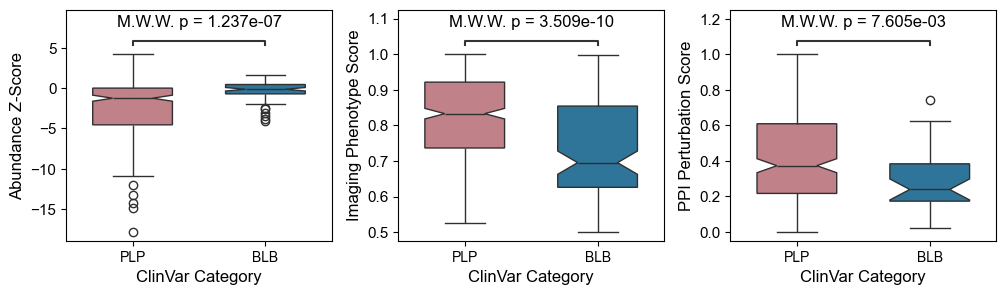

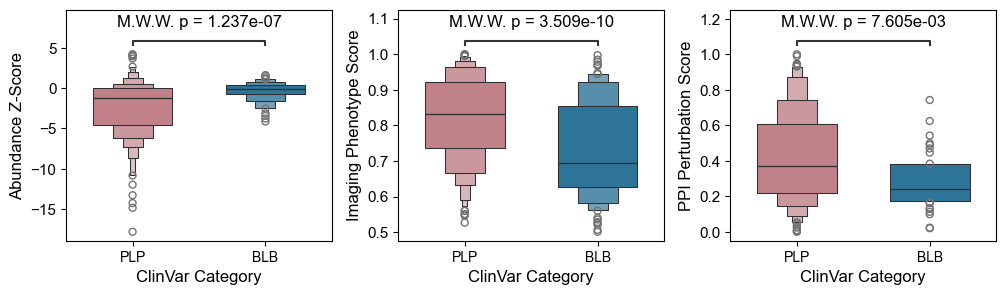

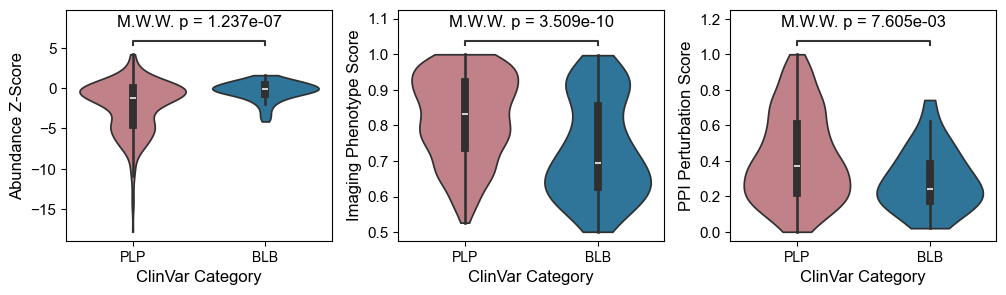

In [48]:
def plot_assay_scores(df, type="box"):
    fig, axes = plt.subplots(1, 3, figsize=(12, 3))
    for i, assay in enumerate(["dualipa_score", "imaging_score", "ppi_score"]):
        if type == "box":
            sns.boxplot(
                data=df.filter(
                    pl.col("clinvar_clnsig_clean").is_in(["Pathogenic", "Benign"])
                ).to_pandas(),
                x="clinvar_clnsig_clean",
                y=assay,
                hue="clinvar_clnsig_clean",
                palette=palette_dict["clinvar_clnsig_clean"],
                width=0.6,
                notch=True,
                order=[c for c in clinvar_order_dict["original"] if "Likely" not in c],
                ax=axes[i],
                legend=False
            )
        if type == "boxen":
            sns.boxenplot(
                data=df.filter(
                    pl.col("clinvar_clnsig_clean").is_in(["Pathogenic", "Benign"])
                ).to_pandas(),
                x="clinvar_clnsig_clean",
                y=assay,
                hue="clinvar_clnsig_clean",
                palette=palette_dict["clinvar_clnsig_clean"],
                width=0.6,
                order=[c for c in clinvar_order_dict["original"] if "Likely" not in c],
                ax=axes[i],
                legend=False
            )
        if type == "violin":
            sns.violinplot(
                data=df.filter(
                    pl.col("clinvar_clnsig_clean").is_in(["Pathogenic", "Benign"])
                ).to_pandas(),
                x="clinvar_clnsig_clean",
                y=assay,
                hue="clinvar_clnsig_clean",
                palette=palette_dict["clinvar_clnsig_clean"],
                cut=0,
                order=[c for c in clinvar_order_dict["original"] if "Likely" not in c],
                ax=axes[i],
                legend=False
            )

        axes[i].set_xlim(-0.5, 1.5)
        # Annotator expects the pairs and corresponding x, hue information
        annotator = Annotator(axes[i], 
                            [("Pathogenic", "Benign")], 
                            data=df.filter(
                                        pl.col("clinvar_clnsig_clean").is_in(["Pathogenic", "Benign"]),
                                        pl.col(assay).is_not_null()
                                    ).to_pandas(), 
                            x="clinvar_clnsig_clean", 
                            y=assay,
                            hue="clinvar_clnsig_clean",
                            order=[c for c in clinvar_order_dict["original"] if "Path" in c or "Benign" in c],
                            verbose=False
        )
        annotator.configure(test="Mann-Whitney",#test='Mann-Whitney-gt', 
                            # test_short_name='M.W.W.', 
                            #comparisons_correction="Bonferroni", 
                            text_format='full', loc='inside', text_offset=8,
                            # test_kw={'alternative': 'greater'},  # or 'less'
                            verbose=False)
        annotator.apply_test()
        annotator.annotate(line_offset_to_group=0.05, line_offset=0.15)#.apply_and_annotate() | .apply_test()
        # axes[i].grid(alpha=.2, axis="y")
        axes[i].xaxis.set_major_locator(FixedLocator(range(2)))
        axes[i].set_xticklabels(["PLP","BLB"], fontsize=10)
        axes[i].set_xlabel("ClinVar Category")

    axes[0].set_ylabel("Abundance Z-Score")
    axes[1].set_ylabel("Imaging Phenotype Score")
    axes[2].set_ylabel("PPI Perturbation Score")
    plt.subplots_adjust(wspace=0.25)
    fig.savefig(
        f"../4_manuscript_figures/assay_phenotyping_score_{type}_dist_clinvar.svg",
        format='svg',
        dpi=400,
        bbox_inches='tight',
        transparent=True
    )
    plt.show()

plot_assay_scores(al_dual_img_ppi_assayed_dedup, "box")
plot_assay_scores(al_dual_img_ppi_assayed_dedup, "boxen")
plot_assay_scores(al_dual_img_ppi_assayed_dedup, "violin")

In [49]:
al_dual_img_ppi_assayed_dedup.filter(
    pl.col("imaging_hit").is_not_null(),
    pl.col("clinvar_clnsig_clean").is_in(["Pathogenic", "Benign"]),
)

symbol,aa_change,gene_variant,spdi,nt_change,chr_num,nuc_loc,ref_allele,alt_allele,Chrom,ensembl_gene_id,orf_id,mut_id,ccsb_mutation_id,ccsb_allele_id,ensembl_protein_id,collection,entry_plate_orig,entry_well_orig,entry_plate_conso,entry_well_conso,entry_seq_pool,db_plate,db_well,n2h_plate,n2h_well,dualip_plate,dualip_well,mislocalization_plate,mislocalization_well,entry_sequenced,entry_sequence_confirmation_class,db_sequenced,db_sequence_confirmation_class,n2h_sequenced,n2h_sequence_confirmation_class,n2h_ref_sequence_confirmation_class,…,dualipa_score,dualipa_abun_change,dualipa_abun_chg_dir,dualipa_hit,ppi_num_edges,ppi_euclid_distance,nan_euclid_distance,mean_signed_difference,mean_log2fc,max_perturbation,std_perturbation,cv_perturbation,gini_coefficient,edges_disrupted_pct,max_to_mean_ratio,top3_edges_contribution_pct,median_abs_deviation,normalized_euclid_distance,normalized_nan_euclid_distance,ppi_score,normalized_nan_euclid_distance_normalized,max_perturbation_normalized,clinvar_clnsig_clean_right,ppi_hit,img_U2OS_cc_t_stat,img_U2OS_cc_t_pval,img_U2OS_cc_t_adj_pval,img_U2OS_prot_abun_t_stat,img_U2OS_prot_abun_t_pval,img_U2OS_prot_abun_t_adj_pval,img_Metadata_Bio_Batch,imaging_score,img_misloc_score,img_pheno_hit,img_misloc_hit,img_pheno_hit_strict,imaging_hit
str,str,str,str,str,i64,i64,str,str,str,str,i64,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,f64,f64,f64,f64,f64,…,f64,str,str,bool,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,bool,f64,f64,f64,f64,f64,f64,str,f64,f64,bool,bool,bool,bool
"""ABCD1""","""Arg389Gly""","""ABCD1_Arg389Gly""","""NC_000023.11:153736195:C:G""","""1165C>G""",23,153736195,"""C""","""G""","""X""","""ENSG00000101986""",100008637,0,"""CCSBVarC007023""","""ALE00007021""","""ENSP00000218104.3""","""CEGS2""","""CegsMutGDEh1023""","""H04""","""GDEhDisVCh_40030""","""G07""","""2""","""NULL""","""NULL""","""NULL""","""NULL""","""NULL""","""NULL""","""NULL""","""NULL""",1.0,5.0,0.0,null,0.0,null,null,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,7.214937,0.000175,0.001322,2.00157,0.101735,0.134305,"""2025_01_Batch_13-14""",0.693378,0.573403,false,false,false,false
"""ABCD1""","""Arg518Gln""","""ABCD1_Arg518Gln""","""NC_000023.11:153740156:G:A""","""1553G>A""",23,153740156,"""G""","""A""","""X""","""ENSG00000101986""",100008637,0,"""CCSBVarC007021""","""ALE00007019""","""ENSP00000218104.3""","""CEGS2""","""CegsMutGDEh1023""","""H06""","""GDEhDisVCh_40030""","""H07""","""2""","""NULL""","""NULL""","""NULL""","""NULL""","""NULL""","""NULL""","""NULL""","""NULL""",1.0,1.0,0.0,null,0.0,null,null,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,6.290702,0.000408,0.002325,-0.564297,0.596924,0.645086,"""2025_01_Batch_13-14""",0.784993,0.691867,false,false,false,false
"""AGXT""","""Ala186Val""","""AGXT_Ala186Val""","""NC_000002.12:240873011:C:T""","""557C>T""",2,240873011,"""C""","""T""","""2""","""ENSG00000172482""",70497,3835,"""CCSBVarC008198""","""ALE00008184""","""ENSP00000302620.3""","""Edgotyping3""","""VUSMutGDEh004""","""C05""","""GDEhDisVCh_40002""","""C07""","""2""","""VUSMutGDDh004""","""C05""","""VUSN2Hmut_GDN2h_01""","""F07""","""VUSMutpDEST2_14""","""E06""","""VUSmut_GDEh01""","""F07""",1.0,1.0,1.0,1.0,1.0,1.0,1.0,…,null,null,null,null,1,0.142378,0.142378,-0.142378,-0.368574,0.142378,0.0,0.0,0.0,0.0,1.0,100.0,0.0,0.142378,0.142378,0.161619,0.161619,0.150362,"""Benign""",false,-2.928613,0.022068,0.04865,-4.020407,0.005057,0.009488,"""2024_01_Batch_7-8""",0.728047,0.69137,false,false,false,false
"""AGXT""","""Ala280Val""","""AGXT_Ala280Val""","""NC_000002.12:240875997:C:T""","""839C>T""",2,240875997,"""C""","""T""","""2""","""ENSG00000172482""",70497,3867,"""CCSBVarC008219""","""ALE00008205""","""ENSP00000302620.3""","""Edgotyping3""","""VUSMutGDEh004""","""F08""","""GDEhDisVCh_40002""

In [51]:
for assay in ["dualipa_hit", "imaging_hit", "ppi_hit"]:
    print(assay)
    contingency_table = al_dual_img_ppi_assayed_dedup.filter(
        pl.col(assay).is_not_null(),
        pl.col("clinvar_clnsig_clean").is_in(["Pathogenic", "Benign"]),
    ).group_by(
        [assay, 'clinvar_clnsig_clean']
    ).agg(
        pl.len()
    ).pivot(
        index=assay,
        on='clinvar_clnsig_clean',
        values="len"
    ).sort(
        assay, descending=True
    )
    print(
        contingency_table.select(
            (pl.col("Pathogenic").first() / pl.col("Pathogenic").sum()).alias("Pathogenic_hit_rate"),
            (pl.col("Benign").first() / pl.col("Benign").sum()).alias("Benign_hit_rate")
        )
    )
    table = contingency_table.select(["Pathogenic", "Benign"]).to_numpy()  # Flip so true is first row
    odds_ratio, p_value = fisher_exact(table, alternative='two-sided')
    print(odds_ratio, p_value)

dualipa_hit
shape: (1, 2)
┌─────────────────────┬─────────────────┐
│ Pathogenic_hit_rate ┆ Benign_hit_rate │
│ ---                 ┆ ---             │
│ f64                 ┆ f64             │
╞═════════════════════╪═════════════════╡
│ 0.4                 ┆ 0.070423        │
└─────────────────────┴─────────────────┘
8.8 7.802825514568112e-09
imaging_hit
shape: (1, 2)
┌─────────────────────┬─────────────────┐
│ Pathogenic_hit_rate ┆ Benign_hit_rate │
│ ---                 ┆ ---             │
│ f64                 ┆ f64             │
╞═════════════════════╪═════════════════╡
│ 0.166667            ┆ 0.066667        │
└─────────────────────┴─────────────────┘
2.8 0.006621739987160036
ppi_hit
shape: (1, 2)
┌─────────────────────┬─────────────────┐
│ Pathogenic_hit_rate ┆ Benign_hit_rate │
│ ---                 ┆ ---             │
│ f64                 ┆ f64             │
╞═════════════════════╪═════════════════╡
│ 0.218107            ┆ 0.032258        │
└─────────────────────┴────────────

In [52]:
al_dual_img_ppi_assayed_dedup.unique("symbol")

symbol,aa_change,gene_variant,spdi,nt_change,chr_num,nuc_loc,ref_allele,alt_allele,Chrom,ensembl_gene_id,orf_id,mut_id,ccsb_mutation_id,ccsb_allele_id,ensembl_protein_id,collection,entry_plate_orig,entry_well_orig,entry_plate_conso,entry_well_conso,entry_seq_pool,db_plate,db_well,n2h_plate,n2h_well,dualip_plate,dualip_well,mislocalization_plate,mislocalization_well,entry_sequenced,entry_sequence_confirmation_class,db_sequenced,db_sequence_confirmation_class,n2h_sequenced,n2h_sequence_confirmation_class,n2h_ref_sequence_confirmation_class,…,dualipa_score,dualipa_abun_change,dualipa_abun_chg_dir,dualipa_hit,ppi_num_edges,ppi_euclid_distance,nan_euclid_distance,mean_signed_difference,mean_log2fc,max_perturbation,std_perturbation,cv_perturbation,gini_coefficient,edges_disrupted_pct,max_to_mean_ratio,top3_edges_contribution_pct,median_abs_deviation,normalized_euclid_distance,normalized_nan_euclid_distance,ppi_score,normalized_nan_euclid_distance_normalized,max_perturbation_normalized,clinvar_clnsig_clean_right,ppi_hit,img_U2OS_cc_t_stat,img_U2OS_cc_t_pval,img_U2OS_cc_t_adj_pval,img_U2OS_prot_abun_t_stat,img_U2OS_prot_abun_t_pval,img_U2OS_prot_abun_t_adj_pval,img_Metadata_Bio_Batch,imaging_score,img_misloc_score,img_pheno_hit,img_misloc_hit,img_pheno_hit_strict,imaging_hit
str,str,str,str,str,i64,i64,str,str,str,str,i64,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,f64,f64,f64,f64,f64,…,f64,str,str,bool,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,bool,f64,f64,f64,f64,f64,f64,str,f64,f64,bool,bool,bool,bool
"""ABCD1""","""Arg389Gly""","""ABCD1_Arg389Gly""","""NC_000023.11:153736195:C:G""","""1165C>G""",23,153736195,"""C""","""G""","""X""","""ENSG00000101986""",100008637,0,"""CCSBVarC007023""","""ALE00007021""","""ENSP00000218104.3""","""CEGS2""","""CegsMutGDEh1023""","""H04""","""GDEhDisVCh_40030""","""G07""","""2""","""NULL""","""NULL""","""NULL""","""NULL""","""NULL""","""NULL""","""NULL""","""NULL""",1.0,5.0,0.0,null,0.0,null,null,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,7.214937,0.000175,0.001322,2.00157,0.101735,0.134305,"""2025_01_Batch_13-14""",0.693378,0.573403,false,false,false,false
"""DIABLO""","""Gly224Arg""","""DIABLO_Gly224Arg""","""NC_000012.12:122208431:C:T""","""670G>A""",12,122208431,"""C""","""T""","""12""","""ENSG00000184047""",7038,404,"""CCSBVarC008462""","""ALE00008433""","""ENSP00000442360.2""","""Edgotyping3""","""VUSmut_GDEh11""","""E06""","""NULL""","""NULL""","""NULL""","""NULL""","""NULL""","""NULL""","""NULL""","""VUSMutpDEST2_05""","""D11""","""VUSmut_GDEh11""","""E06""",0.0,null,0.0,null,0.0,null,null,…,-1.727263,"""Uncertain""","""Decrease""",false,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,-1.797381,0.170126,0.247668,1.652982,0.149421,0.188964,"""2024_01_Batch_7-8""",0.636258,0.606624,false,false,false,false
"""HGD""","""Ala48Ser""","""HGD_Ala48Ser""","""NC_000003.12:120674935:C:A""","""142G>T""",3,120674935,"""C""","""A""","""3""","""ENSG00000113924""",14910,990,"""CCSBVarC008488""","""ALE00008426""","""ENSP00000283871.5""","""Edgotyping3""","""VUSmut_GDEh11""","""E05""","""NULL""","""NULL""","""NULL""","""NULL""","""NULL""","""NULL""","""NULL""","""VUSMutpDEST2_11""","""C09""","""VUSmut_GDEh11""","""E05""",0.0,null,0.0,null,0.0,null,null,…,-0.748527,"""Uncertain""","""Decrease""",false,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,8.728416,0.000052,0.000585,8.612331,0.000057,0.000265,"""2025_03_Batch_15-16""",0.903798,0.831313,false,false,false,false
"""WRAP53""","""Arg398Trp""","""WRAP53_Arg398Trp""","""NC_000017.11:7702770:C:T""","""1192C>T""",17,7702770,"""C""","""T""","""17""","""ENSG00000141499""",5385,201906,"""CCSBVarC003791""","""ALE00003791""","""ENSP00000379727.3""","""CEGS2""","""CegsMutGDEh1031""","""F05""","""GDEhDisVCh_40088""","""

## 2. Plot Gene-level Summary per Assay

In [53]:
def explained_gene_per_assay(assay_df, show_plot=False, benign_thres=1e-3, pathogenic_thres=1e-3, palette_name="clinvar_clnsig_clean"):
    """
    Analyze gene-level performance in functional assays with classification.

    Returns all genes with hit percentages and classification based on thresholds.
    """
    df = plot_gene_level_summary(
        assay_df,
        assay="assay_hit",
        cat="clinvar_clnsig_clean",
        plot=show_plot,
        palette=palette_dict[palette_name]
    ).to_pandas()

    # Create pivot table to get hit percentages by gene and clinvar category
    # display(df)
    gene_summary = df.pivot(index='symbol', columns='clinvar_clnsig_clean', values='hit_perc').fillna(0)
    
    # Get benign and pathogenic columns (if they exist)
    benign_col = 'Benign' if 'Benign' in gene_summary.columns else None
    pathogenic_col = 'Pathogenic' if 'Pathogenic' in gene_summary.columns else None

    # Add classification column based on criteria
    def classify_gene(row):
        benign_rate = row[benign_col] if benign_col else float('inf')
        pathogenic_rate = row[pathogenic_col] if pathogenic_col else 0

        # Meets both criteria (low false positive, high true positive)
        if benign_col and pathogenic_col:
            if benign_rate < benign_thres and pathogenic_rate > pathogenic_thres:
                return "High_Discriminatory"
            elif benign_rate >= benign_thres and pathogenic_rate <= pathogenic_thres:
                return "Low_Discriminatory"
            elif benign_rate < benign_thres and pathogenic_rate <= pathogenic_thres:
                return "Low_Sensitivity"
            elif benign_rate >= benign_thres and pathogenic_rate > pathogenic_thres:
                return "High_False_Positive"
            else:
                return "Unclear"
        elif benign_col:
            return "Low_FP" if benign_rate < benign_thres else "High_FP"
        elif pathogenic_col:
            return "High_Sensitivity" if pathogenic_rate > pathogenic_thres else "Low_Sensitivity"
        else:
            return "No_Classification"

    # Add simple pass/fail column
    def passes_threshold(row):
        benign_rate = row[benign_col] if benign_col else float('inf')
        pathogenic_rate = row[pathogenic_col] if pathogenic_col else 0

        if benign_col and pathogenic_col:
            return (benign_rate < benign_thres) and (pathogenic_rate > pathogenic_thres)
        elif benign_col:
            return benign_rate < benign_thres
        elif pathogenic_col:
            return pathogenic_rate > pathogenic_thres
        else:
            return False

    # Apply classification and pass/fail
    gene_summary['Classification'] = gene_summary.apply(classify_gene, axis=1)
    gene_summary['Passes_Threshold'] = gene_summary.apply(passes_threshold, axis=1)

    # Add summary statistics
    gene_summary_with_stats = gene_summary.copy()

    # Count variants by adding total counts from original df
    variant_counts = df.groupby('symbol').agg({
        'total_counts': 'first',
        'total_counts_all': 'first',
        'hit_counts': 'first'
    })
    gene_summary_with_stats = gene_summary_with_stats.join(variant_counts, how='left')

    # --- Fisher's exact test comparing Pathogenic vs Benign hits per gene ---
    # Prepare aggregated counts from df (symbol x clinvar)
    # df has columns: symbol, clinvar_clnsig_clean, total_counts, hit_counts
    fisher_df = None
    agg = df.groupby(['symbol', 'clinvar_clnsig_clean']).agg({
        'hit_counts': 'sum',
        'total_counts': 'sum'
    }).reset_index()

    # iterate genes in gene_summary_with_stats
    records = []
    for gene in gene_summary_with_stats.index:
        sub = agg[agg['symbol'] == gene]
        # pathogenic
        p_row = sub[sub['clinvar_clnsig_clean'] == 'Pathogenic']
        ph = int(p_row['hit_counts'].sum()) if not p_row.empty else 0
        pt = int(p_row['total_counts'].sum()) if not p_row.empty else 0
        # benign
        b_row = sub[sub['clinvar_clnsig_clean'] == 'Benign']
        bh = int(b_row['hit_counts'].sum()) if not b_row.empty else 0
        bt = int(b_row['total_counts'].sum()) if not b_row.empty else 0

        # non-hit counts
        p_non = max(0, pt - ph)
        b_non = max(0, bt - bh)

        odds, pval = np.nan, np.nan
        # require at least one observation in the 2x2 table
        if (pt + bt) > 0:
            try:
                odds, pval = fisher_exact([[ph, p_non], [bh, b_non]], alternative='two-sided')
            except Exception:
                odds, pval = np.nan, np.nan

        records.append({
            'symbol': gene,
            'fisher_oddsratio': odds,
            'fisher_pval': pval,
            'pathogenic_hit': ph,
            'pathogenic_total': pt,
            'pathogenic_nonhit': p_non,
            'benign_hit': bh,
            'benign_total': bt,
            'benign_nonhit': b_non
        })

    fisher_df = pd.DataFrame.from_records(records).set_index('symbol')
    gene_summary_with_stats = gene_summary_with_stats.join(fisher_df, how='left')

    # Print summary statistics
    classification_counts = gene_summary['Classification'].value_counts()
    passes_count = gene_summary['Passes_Threshold'].sum()
    # print(f"Gene Classification Summary (n={len(gene_summary)} genes):")
    # for classification, count in classification_counts.items():
    #     print(f"  {classification}: {count} genes")

    print(f"\nGenes passing threshold: {passes_count}/{len(gene_summary)} ({passes_count/len(gene_summary)*100:.1f}%)")

    if benign_col and pathogenic_col:
        high_disc_genes = gene_summary[gene_summary['Passes_Threshold'] == True]
        print(f"Genes passing criteria (benign < {benign_thres}% AND pathogenic > {pathogenic_thres}%): {len(high_disc_genes)}")
        # if len(high_disc_genes) > 0:
        #     print("Genes:", sorted(high_disc_genes.index.tolist()))

    return gene_summary_with_stats

In [54]:
genes_with_patho_variants = al_dual_img_ppi_assayed_dedup.filter(
    pl.col("clinvar_clnsig_clean").is_in(["Pathogenic"])
).unique("symbol")["symbol"].to_list()

dual_ipa_gene = explained_gene_per_assay(al_dual_img_ppi_assayed_dedup.filter(
    pl.col("dualipa_abun_change").is_not_null(),
    pl.col("symbol").is_in(genes_with_patho_variants)
).with_columns(
    pl.when(pl.col("dualipa_abun_change")=="Y")
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("assay_hit")
))

imaging_gene = explained_gene_per_assay(al_dual_img_ppi_assayed_dedup.filter(
    pl.col("img_pheno_hit").is_not_null(),
    pl.col("symbol").is_in(genes_with_patho_variants)
).with_columns(
    pl.when(pl.col("img_pheno_hit"))
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("assay_hit")
))

ppi_gene = explained_gene_per_assay(al_dual_img_ppi_assayed_dedup.filter(
    pl.col("ppi_hit").is_not_null(),
    pl.col("symbol").is_in(genes_with_patho_variants)
).with_columns(
    pl.when(pl.col("ppi_hit"))
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("assay_hit")
))


Genes passing threshold: 44/71 (62.0%)
Genes passing criteria (benign < 0.001% AND pathogenic > 0.001%): 44

Genes passing threshold: 22/88 (25.0%)
Genes passing criteria (benign < 0.001% AND pathogenic > 0.001%): 22

Genes passing threshold: 15/64 (23.4%)
Genes passing criteria (benign < 0.001% AND pathogenic > 0.001%): 15


### Three assays tested

In [55]:
# Merge imaging_gene and dual_ipa_gene based on union of their indices
merged_genes_any_path = imaging_gene.join(dual_ipa_gene, how='outer', lsuffix='_imaging', rsuffix='_dualipa')
merged_genes_any_path = merged_genes_any_path.join(ppi_gene, how='outer', rsuffix='_ppi')

# Display the merged result
print(f"Imaging genes: {len(imaging_gene)}")
print(f"Dual-IPA genes: {len(dual_ipa_gene)}")
print(f"PPI genes: {len(ppi_gene)}")
print(f"Merged genes (union): {len(merged_genes_any_path)}")
print(f"Genes in ALL three assays: {len(set(imaging_gene.index).intersection(set(dual_ipa_gene.index)).intersection(set(ppi_gene.index)))}")

merged_genes_any_path[["Passes_Threshold_imaging", "Passes_Threshold_dualipa", "Passes_Threshold"]]
merged_genes_any_path["true_count"] = merged_genes_any_path[["Passes_Threshold_imaging", "Passes_Threshold_dualipa", "Passes_Threshold"]].sum(axis=1)
merged_genes_any_path["non_null_count"] = merged_genes_any_path[["Passes_Threshold_imaging", "Passes_Threshold_dualipa", "Passes_Threshold"]].notna().sum(axis=1)
merged_genes_any_path = merged_genes_any_path.sort_values(by=["non_null_count","true_count"], ascending=[False,False])

overlapped_genes_any_path = list(set(imaging_gene.index).intersection(set(dual_ipa_gene.index)).intersection(set(ppi_gene.index)))
# Prepare data for heatmap - handle NaN values properly
heatmap_data = merged_genes_any_path.loc[overlapped_genes_any_path,["Passes_Threshold_imaging", "Passes_Threshold_dualipa", "Passes_Threshold"]].rename(
    {
        "Passes_Threshold_imaging": "Imaging",
        "Passes_Threshold_dualipa": "DUAL-IPA",
        "Passes_Threshold": "PPI"
    }, axis=1
).copy()

overlapped_genes = list(set(imaging_gene.index).intersection(set(dual_ipa_gene.index)).intersection(set(ppi_gene.index)))

# Prepare data for heatmap - handle NaN values properly
heatmap_data = merged_genes_any_path.loc[overlapped_genes,["Passes_Threshold_dualipa", "Passes_Threshold_imaging", "Passes_Threshold"]].rename(
    {
        "Passes_Threshold_dualipa": "Abundance",
        "Passes_Threshold_imaging": "Imaging",
        "Passes_Threshold": "PPI"
    }, axis=1
).copy()

Imaging genes: 88
Dual-IPA genes: 71
PPI genes: 64
Merged genes (union): 123
Genes in ALL three assays: 29


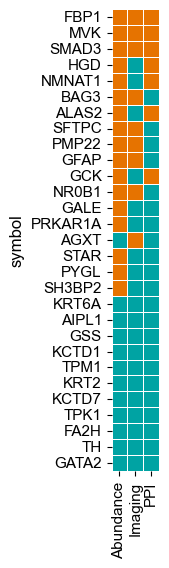

Hit rate: 62.069%


In [56]:
# Sort by row sum (total number of assays passed) - largest to smallest
# First calculate row sums treating NaN as 0 for sorting purposes
row_sums = heatmap_data.fillna(0).sum(axis=1)
sort_order = row_sums.sort_values(ascending=False).index
heatmap_data = heatmap_data.loc[sort_order]

# Create mask AFTER sorting
mask = heatmap_data.isna()

# Convert boolean to int, but keep NaN as NaN initially
heatmap_data_filled = heatmap_data.astype(float)  # Keep as float to preserve NaN

# Create custom colormap: blue for False (0), red for True (1)
colors = ['#00A3A3', '#E67300']  # blue, red
custom_cmap = ListedColormap(colors)

# Set the bad color (for masked values) to light grey
custom_cmap.set_bad(color='lightgrey')

fig, ax = plt.subplots(1,1,figsize=(6,6))
sns.heatmap(heatmap_data_filled, 
            # mask=panel1_mask,
            cmap=custom_cmap, 
            square=True,
            cbar=False,
            linewidths=0.5,
            linecolor='white',
            ax=ax,
            yticklabels=True,
            vmin=0, vmax=1
)
plt.show()

hit_rate = heatmap_data_filled.loc[heatmap_data_filled.sum(axis=1) > 0,:].shape[0] / heatmap_data_filled.shape[0]
print(f"Hit rate: {hit_rate*100:.3f}%")

In [57]:
heatmap_data.shape

(29, 3)

In [20]:
plt.clf()
# Prepare data for heatmap - handle NaN values properly
heatmap_data = merged_genes_any_path.loc[:,["Passes_Threshold_dualipa", "Passes_Threshold_imaging", "Passes_Threshold"]].rename(
    {
        "Passes_Threshold_dualipa": "Abundance",
        "Passes_Threshold_imaging": "Imaging",
        "Passes_Threshold": "PPI"
    }, axis=1
).copy()

heatmap_data["Row_NA_sum"] = heatmap_data.isna().sum(axis=1)

In [16]:
# # Prepare data for heatmap - handle NaN values properly
# heatmap_data = merged_genes[["Passes_Threshold_imaging", "Passes_Threshold_dualipa", "Passes_Threshold"]].rename(
#     {
#         "Passes_Threshold_imaging": "Imaging",
#         "Passes_Threshold_dualipa": "DUAL-IPA",
#         "Passes_Threshold": "PPI"
#     }, axis=1
# ).copy()

# # Sort by row sum (total number of assays passed) - largest to smallest
# # First calculate row sums treating NaN as 0 for sorting purposes
# row_sums = heatmap_data.fillna(0).sum(axis=1)
# sort_order = row_sums.sort_values(ascending=False).index
# heatmap_data = heatmap_data.loc[sort_order]

# # Create mask AFTER sorting
# mask = heatmap_data.isna()

# # Convert boolean to int, but keep NaN as NaN initially
# heatmap_data_filled = heatmap_data.astype(float)  # Keep as float to preserve NaN

# # Create custom colormap: blue for False (0), red for True (1)
# colors = ['#1f77b4', '#d62728']  # blue, red
# custom_cmap = ListedColormap(colors)

# # Set the bad color (for masked values) to light grey
# custom_cmap.set_bad(color='lightgrey')

# # Split into 3 horizontal panels with ~50 genes each
# n_genes = len(heatmap_data_filled)
# genes_per_panel = 52
# n_panels = 3
# genes_panel1 = min(genes_per_panel, n_genes)
# genes_panel2 = min(genes_per_panel, max(0, n_genes - genes_panel1))
# genes_panel3 = max(0, n_genes - genes_panel1 - genes_panel2)

# # Use gridspec for better control over spacing
# from matplotlib.gridspec import GridSpec
# fig = plt.figure(figsize=(18, 15))
# gs = GridSpec(1, 3, width_ratios=[1, 1, .67], wspace=-.94)  # Extra width for panel 3 colorbar
# axes = [fig.add_subplot(gs[0, i]) for i in range(3)]

# # Panel 1: First ~50 genes
# if genes_panel1 > 0:
#     panel1_data = heatmap_data_filled.iloc[:genes_panel1]
#     panel1_mask = mask.iloc[:genes_panel1]
#     sns.heatmap(panel1_data, 
#                 mask=panel1_mask,
#                 cmap=custom_cmap, 
#                 square=True,
#                 cbar=False,
#                 linewidths=0.5,
#                 linecolor='white',
#                 ax=axes[0],
#                 yticklabels=True,
#                 vmin=0, vmax=1
#                 )
#     axes[0].set_ylabel('Gene Symbol', fontsize=10)
#     axes[0].set_xlabel('Assay Type')
#     axes[0].set_title(f'Functional Assay\nDistinguishable Genes')
#     axes[0].tick_params(axis='y', labelsize=9)

# # Panel 2: Next ~50 genes
# if genes_panel2 > 0:
#     panel2_data = heatmap_data_filled.iloc[genes_panel1:genes_panel1+genes_panel2]
#     panel2_mask = mask.iloc[genes_panel1:genes_panel1+genes_panel2]
    
#     sns.heatmap(panel2_data, 
#                 mask=panel2_mask,
#                 cmap=custom_cmap, 
#                 square=True,
#                 cbar=False,
#                 linewidths=0.5,
#                 linecolor='white',
#                 ax=axes[1],
#                 yticklabels=True,
#                 vmin=0, vmax=1
#                 )
#     axes[1].set_ylabel('')
#     axes[1].set_xlabel('Assay Type')
#     axes[1].set_title(f'Functional Assay\nNon-Distinguishable Genes')
#     axes[1].tick_params(axis='y', labelsize=9)
# else:
#     axes[1].set_visible(False)

# # Panel 3: Remaining genes
# if genes_panel3 > 0:
#     panel3_data = heatmap_data_filled.iloc[genes_panel1+genes_panel2:]
#     panel3_mask = mask.iloc[genes_panel1+genes_panel2:]
    
#     sns.heatmap(panel3_data, 
#                 mask=panel3_mask,
#                 cmap=custom_cmap, 
#                 square=True,
#                 cbar_kws={'ticks': [0, 1], 'label': 'Distinguish\nPathogenic vs Benign', 'shrink': 0.3, 'format': FixedFormatter(['False', 'True'])},
#                 linewidths=0.5,
#                 linecolor='white',
#                 ax=axes[2],
#                 yticklabels=True,
#                 vmin=0, vmax=1
#                 )
#     axes[2].set_ylabel('')
#     axes[2].set_xlabel('Assay Type')
#     axes[2].set_title(f'Functional Assay\nNon-Distinguishable Genes')
#     axes[2].tick_params(axis='y', labelsize=9)
# else:
#     axes[2].set_visible(False)

# # plt.suptitle('Gene Performance Across Assays (Sorted by Total Passes)\n(Red=Pass, Blue=Fail, Grey=No Data)', y=0.95)
# plt.show()
# # merged_genes

<Figure size 640x480 with 0 Axes>

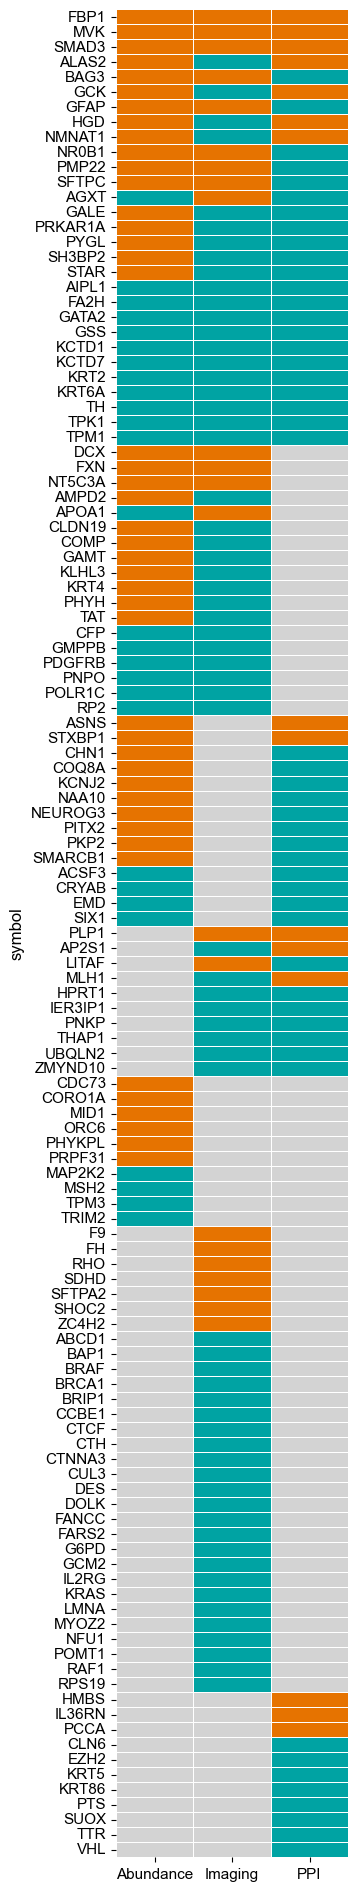

In [50]:
plt.clf()
# Prepare data for heatmap - handle NaN values properly
heatmap_data = merged_genes_any_path.loc[:,["Passes_Threshold_dualipa", "Passes_Threshold_imaging", "Passes_Threshold"]].rename(
    {
        "Passes_Threshold_dualipa": "Abundance",
        "Passes_Threshold_imaging": "Imaging",
        "Passes_Threshold": "PPI"
    }, axis=1
).copy()

heatmap_data["Row_NA_sum"] = heatmap_data.isna().sum(axis=1)
heatmap_data["Row_Sum"] = heatmap_data[["Abundance","Imaging","PPI"]].sum(axis=1)
heatmap_data["Row_Abun"] = heatmap_data[["Abundance"]].isna()
heatmap_data["Row_Img"] = heatmap_data[["Imaging"]].isna()
heatmap_data["Row_PPI"] = heatmap_data[["PPI"]].isna()

heatmap_data["Gene"] = heatmap_data.index

heatmap_data = heatmap_data.sort_values(
    by=["Row_NA_sum", "Row_Abun", "Row_Img", "Row_PPI", "Row_Sum", "Gene"], ##, 
    ascending=[True, True, True, True, False, True]
)

# Create mask AFTER sorting
mask = heatmap_data[["Abundance", "Imaging", "PPI"]].isna()

# Convert boolean to int, but keep NaN as NaN initially
heatmap_data_filled = heatmap_data[["Abundance", "Imaging", "PPI"]].astype(float)  # Keep as float to preserve NaN

# Create custom colormap: blue for False (0), red for True (1)
colors = ['#00A3A3', '#E67300']  # blue, red
custom_cmap = ListedColormap(colors)

# Set the bad color (for masked values) to light grey
custom_cmap.set_bad(color='lightgrey')

fig, ax = plt.subplots(1,1,figsize=(3,24))
sns.heatmap(heatmap_data_filled, 
            # mask=panel1_mask,
            cmap=custom_cmap, 
            # square=True,
            cbar=False,
            linewidths=0.5,
            linecolor='white',
            ax=ax,
            yticklabels=True,
            vmin=0, vmax=1
)
# plt.tight_layout()
plt.savefig("../4_manuscript_figures/assay_hit_per_gene.svg", dpi=400, transparent=True, bbox_inches='tight')
plt.show()

In [33]:
# plt.clf()
# # Prepare data for heatmap - handle NaN values properly
# heatmap_data = merged_genes_any_path.loc[:,["Passes_Threshold_dualipa", "Passes_Threshold_imaging", "Passes_Threshold"]].rename(
#     {
#         "Passes_Threshold_dualipa": "Abundance",
#         "Passes_Threshold_imaging": "Imaging",
#         "Passes_Threshold": "PPI"
#     }, axis=1
# ).copy()

# # Sort by row sum (total number of assays passed) - largest to smallest
# # First calculate row sums treating NaN as 0 for sorting purposes
# row_sums = heatmap_data.fillna(0).sum(axis=1)
# sort_order = row_sums.sort_values(ascending=False).index
# heatmap_data = heatmap_data.loc[sort_order]

# # Create mask AFTER sorting
# mask = heatmap_data.isna()
# # Convert boolean to int, but keep NaN as NaN initially
# heatmap_data_filled = heatmap_data.astype(float)  # Keep as float to preserve NaN

# genes_panel1 = merged_genes_any_path[merged_genes_any_path["non_null_count"]==3].index
# genes_panel2 = merged_genes_any_path[merged_genes_any_path["non_null_count"]==2].index
# genes_panel3 = merged_genes_any_path[merged_genes_any_path["non_null_count"]==1].index

# # Use gridspec for better control over spacing
# # Calculate proportional widths based on gene counts
# n1, n2, n3 = len(genes_panel1), len(genes_panel2), len(genes_panel3)
# total = n1 + n2 + n3

# fig = plt.figure(figsize=(10, 10))
# # gs = GridSpec(1, 3, 
# #               width_ratios=[n1/total, n2/total, n3/total],  # Proportional to gene count
# #               wspace=0.3)  # Positive value for consistent spacing
# # [left, bottom, width, height] in figure coordinates
# # axes = [fig.add_subplot(gs[0, i]) for i in range(3)]

# ax1 = fig.add_axes([0.06, 0.1, 0.1, 0.8])   # Panel 1
# ax2 = fig.add_axes([0.185, 0.1, 0.22, 0.8])   # Panel 2 (gap = 0.02)
# ax3 = fig.add_axes([0.27, 0.1, 0.40, 0.8])   # Panel 3 (gap = 0.07)
# axes = [ax1, ax2, ax3]

# # Panel 1: First ~50 genes
# if len(genes_panel1) > 0:
#     panel1_data = heatmap_data_filled.loc[genes_panel1,]
#     panel1_mask = mask.loc[genes_panel1,]
#     sns.heatmap(panel1_data, 
#                 mask=panel1_mask,
#                 cmap=custom_cmap, 
#                 # square=True,
#                 cbar=False,
#                 linewidths=0.5,
#                 linecolor='white',
#                 ax=axes[0],
#                 yticklabels=True,
#                 vmin=0, vmax=1
#                 )
#     axes[0].set_ylabel('Gene Symbol', fontsize=10)
#     axes[0].set_xlabel('Assay Type')
#     axes[0].set_title(f'3 Assays Profiled')
#     axes[0].tick_params(axis='y', labelsize=9)
#     axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=90) #, ha="right"
#     # axes[0].set_aspect(0.5)

# # Panel 2: Next ~50 genes
# if len(genes_panel2) > 0:
#     panel2_data = heatmap_data_filled.loc[genes_panel2,]
#     panel2_mask = mask.loc[genes_panel2,]
    
#     sns.heatmap(panel2_data, 
#                 mask=panel2_mask,
#                 cmap=custom_cmap, 
#                 # square=True,
#                 cbar=False,
#                 linewidths=0.5,
#                 linecolor='white',
#                 ax=axes[1],
#                 yticklabels=True,
#                 vmin=0, vmax=1
#                 )
#     axes[1].set_ylabel('')
#     axes[1].set_xlabel('Assay Type')
#     axes[1].set_title(f'2 Assays Profiled')
#     axes[1].tick_params(axis='y', labelsize=9)
#     axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=90) #, ha="right"
#     axes[1].set_aspect(0.5)
# else:
#     axes[1].set_visible(False)

# # Panel 3: Remaining genes
# if len(genes_panel3) > 0:
#     panel3_data = heatmap_data_filled.loc[genes_panel3,]
#     panel3_mask = mask.loc[genes_panel3,]
    
#     sns.heatmap(panel3_data, 
#                 mask=panel3_mask,
#                 cmap=custom_cmap, 
#                 # square=True,
#                 cbar=False,
#                 # cbar_kws={'ticks': [0, 1], 'label': 'Phenotype Hit', 'shrink': 0.1, 'format': 
#                 # FixedFormatter(['False', 'True'])},
#                 linewidths=0.5,
#                 linecolor='white',
#                 ax=axes[2],
#                 yticklabels=True,
#                 vmin=0, vmax=1
#                 )
#     axes[2].set_ylabel('')
#     axes[2].set_xlabel('Assay Type')
#     axes[2].set_title(f'1 Assay Profiled')
#     axes[2].tick_params(axis='y', labelsize=9)
#     axes[2].set_xticklabels(axes[2].get_xticklabels(), rotation=90) #, ha="center"
#     axes[2].set_aspect(0.5)
# else:
#     axes[2].set_visible(False)

# # Manual colorbar as legend
# legend_elements = [
#     Patch(facecolor='#E67300', edgecolor='white', label='True'),
#     Patch(facecolor='#00A3A3', edgecolor='white', label='False'),
#     Patch(facecolor='lightgrey', edgecolor='white', label='No Data')
# ]

# # Position legend on right side
# fig.legend(
#     handles=legend_elements,
#     loc='center right',
#     title='Assay Hit',
#     frameon=True,
#     bbox_to_anchor=(0.66, 0.5)
# )
# # plt.suptitle('Gene Performance Across Assays (Sorted by Total Passes)\n(Red=Pass, Blue=Fail, Grey=No Data)', y=0.95)
# plt.tight_layout()
# plt.savefig("../4_manuscript_figures/assay_hit_per_gene.svg", dpi=400, transparent=True, bbox_inches='tight')
# plt.show()
# # merged_genes

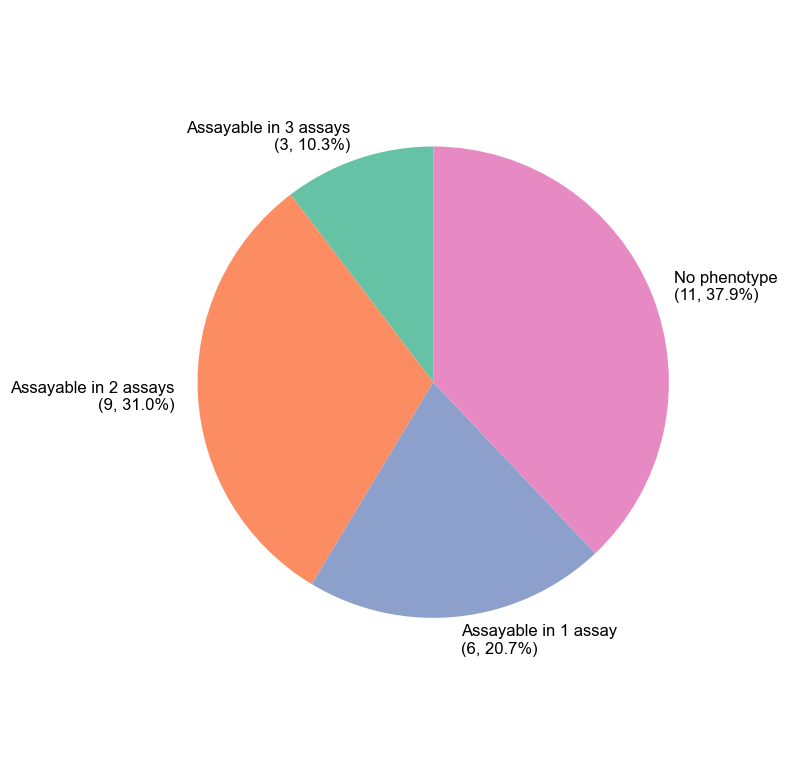

Assayable in 3 assays: 3 genes (10.3%)
Assayable in 2 assays: 9 genes (31.0%)
Assayable in 1 assay: 6 genes (20.7%)
No phenotype: 11 genes (37.9%)

Total genes: 29


In [38]:
# Create pie chart for ClinVar annotation categories
merged_genes_any_path_pl = pl.DataFrame(merged_genes_any_path).with_columns(
    pl.when(pl.col("true_count")==0)
    .then(pl.lit("No phenotype"))
    .when(pl.col("true_count")==1)
    .then(pl.lit("Assayable in 1 assay"))
    .when(pl.col("true_count")==2)
    .then(pl.lit("Assayable in 2 assays"))
    .otherwise(pl.lit("Assayable in 3 assays"))
    .alias("Assayable")
).filter(
    pl.col("non_null_count")==3
)
# Get the category counts from the merged data
summary_clin_var_counts = merged_genes_any_path_pl.group_by("Assayable").len() #.sort("clinvar_clnsig_clean")#.sort("len", descending=True)
summary_clin_var_counts = merged_genes_any_path_pl.group_by("Assayable").len().to_pandas()
category_order = ["Assayable in 3 assays", "Assayable in 2 assays", "Assayable in 1 assay", "No phenotype"]
summary_clin_var_counts['Assayable'] = pd.Categorical(summary_clin_var_counts['Assayable'], categories=category_order, ordered=True)

# Convert to pandas for easier plotting
pie_data = summary_clin_var_counts.sort_values('Assayable')
pie_data = pie_data.dropna()  # Remove any null values

# Calculate percentages
total_count = pie_data["len"].sum()
pie_data["percentage"] = (pie_data["len"] / total_count * 100).round(1)

# Create labels with counts and percentages
labels = [f"{cat}\n({count}, {pct}%)" 
          for cat, count, pct in zip(pie_data["Assayable"], 
                                   pie_data["len"], 
                                   pie_data["percentage"])]

# Use a color palette that matches the boxenplot
# colors = list(palette_dict["clinvar_clnsig_clean"].values())
# colors[1], colors[3] = colors[3], colors[1]  # Swap colors to match the order in pie chart
# Create pie chart
fig, ax = plt.subplots(1, 1, figsize=(8, 8))
wedges, texts, autotexts = ax.pie(pie_data["len"], 
                                  labels=labels, 
                                  colors=sns.color_palette("Set2"),
                                  autopct="",  # We're including percentages in labels
                                  startangle=90,
                                  textprops={'fontsize': 12})

# ax.set_title("Distribution of Molecular Phenotype Detection Rate", y=.90, fontsize=14, fontweight='bold', pad=0)
# Equal aspect ratio ensures that pie is drawn as a circle
ax.axis('equal')

# # Add a legend
# ax.legend(wedges, [f"{cat} (n={count})" for cat, count in zip(pie_data["clinvar_clnsig_clean"], pie_data["len"])],
#           title="Categories",
#           loc="center left",
#           bbox_to_anchor=(1, 0, 0.5, 1))

plt.tight_layout()
plt.savefig("../4_manuscript_figures/gene_assayability.svg", dpi=400, transparent=True, bbox_inches='tight')
plt.show()

# Print summary statistics
print("=" * 40)
for _, row in pie_data.iterrows():
    print(f"{row['Assayable']}: {row['len']} genes ({row['percentage']}%)")
print(f"\nTotal genes: {total_count}")

### 3.2 VUS analyses

In [ ]:
vus = al_dual_img_ppi_assayed_dedup.filter(
    (pl.col("clinvar_clnsig_clean_pp_strict") == "VUS")
)

vus_detailed = vus.with_columns(
    pl.col("dualipa_score").is_not_null().alias("tested_DUAL-IPA"),
    pl.col("imaging_score").is_not_null().alias("tested_Imaging"),
    pl.col("ppi_score").is_not_null().alias("tested_PPI"),
    pl.when(pl.col("dualipa_abun_change")=="Y")
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("hit_DUAL-IPA"),
    pl.when(pl.col("img_pheno_hit"))
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("hit_Imaging"),
    pl.col("ppi_hit").alias("hit_PPI")
).select([
    "symbol",
    "gene_variant",
    "nt_change",
    "aa_change",
    "spdi",
    "tested_DUAL-IPA",
    "tested_Imaging", 
    "tested_PPI",
    "hit_DUAL-IPA",
    "hit_Imaging",
    "hit_PPI",
    "dualipa_score",
    "imaging_score",
    "ppi_score"
]).sort("symbol", "gene_variant")
display(vus_detailed)

# Also create a summary per gene
vus_gene_summary = vus_detailed.group_by("symbol").agg([
    pl.len().alias("num_VUS"),
    pl.col("tested_DUAL-IPA").sum().alias("tested_DUAL-IPA"),
    pl.col("tested_Imaging").sum().alias("tested_Imaging"),
    pl.col("tested_PPI").sum().alias("tested_PPI"),
    pl.col("hit_DUAL-IPA").sum().alias("hit_DUAL-IPA"),
    pl.col("hit_Imaging").sum().alias("hit_Imaging"),
    pl.col("hit_PPI").sum().alias("hit_PPI")
]).with_columns([
    (pl.col("hit_DUAL-IPA") / pl.col("tested_DUAL-IPA") * 100).round(1).alias("hit_rate_DUAL-IPA_perc"),
    (pl.col("hit_Imaging") / pl.col("tested_Imaging") * 100).round(1).alias("hit_rate_Imaging_perc"),
    (pl.col("hit_PPI") / pl.col("tested_PPI") * 100).round(1).alias("hit_rate_PPI_perc")
]).sort("num_VUS", descending=True)

# Display both tables
# print("VUS Detailed Table (first 10 rows):")
# display(vus_detailed.head(10))

# print("\nVUS Gene Summary Table:")
# display(vus_gene_summary)

# vus.group_by("symbol").agg(
#     pl.len().alias("num_VUS")
# ).sort("num_VUS", descending=True).write_csv("../3_outputs/vus_per_gene.csv", separator=",")

# vus_gene_summary.write_csv("../3_outputs/0_vus_per_gene_with_assay_summary.csv")

# Save detailed VUS table
# vus_detailed.write_csv("../3_outputs/0_vus_detailed_with_assays.csv")



vus_hit_assay = vus_gene_summary.select(
    pl.col('symbol', "hit_rate_DUAL-IPA_perc","hit_rate_Imaging_perc","hit_rate_PPI_perc")
).rename(
    {
        "hit_rate_DUAL-IPA_perc": "Abundance",
        "hit_rate_Imaging_perc": "Imaging",
        "hit_rate_PPI_perc": "PPI"
    }
).to_pandas().set_index("symbol")

vus_hit_assay_sum = vus_hit_assay.apply(lambda x: np.where(x.isna(), np.nan, x > 0))
vus_hit_assay = vus_hit_assay.loc[vus_hit_assay_sum.sum(axis=1).sort_values(ascending=False).index,:]

# Create binary mask: True if > 0, False if == 0, NaN stays NaN
binary_df = vus_hit_assay.apply(lambda x: np.where(x.isna(), np.nan, x > 0))
# Count NaNs per row
nan_counts = binary_df.isna().sum(axis=1)
# Split into three groups
df_0nan = binary_df[nan_counts == 0]  # All assays profiled
df_1nan = binary_df[nan_counts == 1]  # Two assays profiled
df_2nan = binary_df[nan_counts == 2]  # One assay profiled

total_df = vus_gene_summary.select(
    pl.col('symbol', "tested_DUAL-IPA","tested_Imaging","tested_PPI")
).rename(
    {
        "tested_DUAL-IPA": "Abundance",
        "tested_Imaging": "Imaging",
        "tested_PPI": "PPI"
    }
).to_pandas().set_index("symbol")

hits_df = vus_gene_summary.select(
    pl.col('symbol', "hit_DUAL-IPA","hit_Imaging","hit_PPI")
).rename(
    {
        "hit_DUAL-IPA": "Abundance",
        "hit_Imaging": "Imaging",
        "hit_PPI": "PPI"
    }
).to_pandas().set_index("symbol")

# Build string annotation matrix
annot_df = hits_df.astype(int).astype(str) + "/" + total_df.astype(int).astype(str)
annot_df = annot_df.loc[binary_df.index, binary_df.columns]
annot_df = annot_df.where(~vus_hit_assay.isna(), "")  # blank for NaN cells

# Split annotation matrix same way as data
nan_counts = binary_df.isna().sum(axis=1)
annot_0nan = annot_df[nan_counts == 0]
annot_1nan = annot_df[nan_counts == 1]
annot_2nan = annot_df[nan_counts == 2]
annots = [annot_0nan, annot_1nan, annot_2nan]

# Warm/cool palette: cool mint for False, warm orange for True
cmap = ListedColormap(['slateblue', '#E85A1B'])

fig, axes = plt.subplots(1, 3, figsize=(8, max(len(df_0nan), len(df_1nan), len(df_2nan)) * 0.2 + 2))

dfs = [df_0nan, df_1nan, df_2nan]
titles = ['3 Assays Profiled', '2 Assays Profiled', '1 Assay Profiled']

for ax, sub_df, annot_sub, title_base in zip(axes, dfs, annots, titles):
    if len(sub_df) == 0:
        ax.set_visible(False)
        continue
    
    hit_rate = (sub_df.max(axis=1) > 0).mean() * 100
    
    sns.heatmap(
        sub_df.astype(float),
        cmap=cmap,
        vmin=0,
        vmax=1,
        linewidths=0.5,
        linecolor='white',
        cbar=False,
        ax=ax,
        mask=sub_df.isna(),
        annot=annot_sub,
        fmt="s",  # string format
        annot_kws={"fontsize": 10, "font": "arial"}
    )
    
    # Fill NaN cells with grey
    for i in range(sub_df.shape[0]):
        for j in range(sub_df.shape[1]):
            if pd.isna(sub_df.iloc[i, j]):
                ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=True, color='#D3D3D3', ec='white', lw=0.5))
    
    ax.set_title(f'{title_base}') ## \n{hit_rate:.1f}% genes hit (n={len(sub_df)})
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right")
    ax.tick_params(axis='x', pad=0)

axes[0].set_yticklabels(axes[0].get_yticklabels(), rotation=0)
# Shared legend on rightmost axis
legend_elements = [
    Patch(facecolor='#E85A1B', label='Yes'),
    Patch(facecolor='slateblue', label='No'),
    Patch(facecolor='#D3D3D3', label='Not Profiled'),
]
axes[-1].legend(handles=legend_elements, loc='upper left', title="Phenotype Detected", bbox_to_anchor=(1.02, .6))

plt.suptitle("VUS Phenotyping Status Per Gene", fontsize=16, y=.96)
plt.subplots_adjust(wspace=2)
plt.tight_layout()
fig.savefig(
    "../4_manuscript_figures/VUS_phenotype.svg",
    format='svg',
    dpi=300,
    bbox_inches='tight',
    transparent=True
)
plt.show()

In [ ]:
# Count NaNs per row
nan_counts = vus_hit_assay.isna().sum(axis=1)

# Split into three groups
df_0nan = vus_hit_assay[nan_counts == 0]  # All assays profiled
df_1nan = vus_hit_assay[nan_counts == 1]  # Two assays profiled
df_2nan = vus_hit_assay[nan_counts == 2]  # One assay profiled

fig, axes = plt.subplots(1, 3, figsize=(9, max(len(df_0nan), len(df_1nan), len(df_2nan)) * 0.2 + 2))
dfs = [df_0nan, df_1nan, df_2nan]
titles = ['3 Assays Profiled', '2 Assays Profiled', '1 Assay Profiled']
for ax, sub_df, title_base in zip(axes, dfs, titles):
    if len(sub_df) == 0:
        ax.set_visible(False)
        continue
    
    # Calculate hit rate: gene is hit if max value in row > 0
    hit_rate = (sub_df.max(axis=1) > 0).mean() * 100
    
    sns.heatmap(
        sub_df.astype(float),
        cmap="rocket_r",
        vmin=0,
        vmax=100,
        linewidths=0.5,
        linecolor='white',
        cbar=(ax == axes[-1]),  # Only show colorbar on last axis
        cbar_kws={'label': '% of Hit per Assay', 'shrink': 0.3, 'pad': 0.05} if ax == axes[-1] else {},
        ax=ax,
        mask=sub_df.isna(),
        annot=True,
        fmt=".1f"
    )
    # Fill NaN cells with grey
    for i in range(sub_df.shape[0]):
        for j in range(sub_df.shape[1]):
            if pd.isna(sub_df.iloc[i, j]):
                ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=True, color='#D3D3D3', ec='white', lw=0.5))
    
    ax.set_title(f'{title_base}') ## \n{hit_rate:.1f}% genes hit (n={len(sub_df)})
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right")
    ax.tick_params(axis='x', pad=0)

axes[0].set_yticklabels(axes[0].get_yticklabels(), rotation=0)
# Shared legend on rightmost axis
# legend_elements = [
#     Patch(facecolor='#E85A1B', label='Yes'),
#     Patch(facecolor='#A8E6CF', label='No'),
#     Patch(facecolor='#D3D3D3', label='Not Profiled'),
# ]
# axes[-1].legend(loc='upper left', title="Molecular Phenotype", bbox_to_anchor=(1.02, .6))
plt.suptitle("VUS Phenotyping Hit Ratio Per Gene", fontsize=16, y=.96)
plt.subplots_adjust(wspace=1.4)
plt.tight_layout()
fig.savefig(
    "../4_manuscript_figures/VUS_phenotype_ratio.svg",
    format='svg',
    dpi=300,
    bbox_inches='tight',
    transparent=True
)
plt.show()

## 4. Variant-level Analyses

### 4.1 Gene alleles profiled by ALL 3 assays

In [39]:
meta_cols = ["symbol", "gene_variant", "ensembl_gene_id", "spdi", "orf_id", "mut_id", 
             "nt_change", "aa_change", "clinvar_clnsig_clean", "clinvar_clnsig_clean_pp_strict", "gnomAD4.1_joint_AF", "StarStatus",
             "inheritance_pattern", "AlphaMissense_score", "AlphaMissense_rankscore", "AlphaMissense_pred", 
             "ESM1b_score", "ESM1b_rankscore", "ESM1b_pred",
             "plddt_f32", "rsa_f32", "RSA_Category", "pLDDT_Category"]
dualipa_cols = ["dualipa_score", "dualipa_abun_change", "dualipa_abun_chg_dir"]
img_cols = ["imaging_score", "img_pheno_hit"] ## "AUROC_Mean_DNA", "Altered_95th_perc_both_batches_DNA"
ppi_cols = ["ppi_score", "ppi_hit"]

al_dual_img_ppi_key_cols = al_dual_img_ppi_assayed_dedup.select(
    pl.col(meta_cols + dualipa_cols + img_cols + ppi_cols)
)

### 3.2 Gene Alleles Profiled by AT LEAST ONE assay

In [40]:
alleles_prof_one_assay = al_dual_img_ppi_key_cols.filter(
    ~pl.all_horizontal([pl.col(col).is_null() for col in dualipa_cols+img_cols+ppi_cols])
).unique(subset="gene_variant")
alleles_prof_one_assay.shape

(1421, 30)

In [28]:
# palette_dict = {
#     "clinvar_clnsig_clean":{
#         '1_Pathogenic': "#CA7682",
#         '2_Benign': "#1D7AAB",
#         '3_Conflicting': "#E6B1B8", #"grey",
#         '4_VUS': "#A0A0A0",
#         '5_Others': "#A0A0A0"
#         # '6_No_ClinVar'
#     }
# }

# fig, axes = plt.subplots(1,3,figsize=(18,5))
# plot_cat_count_perc(
#     alleles_prof_one_assay,
#     "clinvar_clnsig_clean",
#     title="ClinVar",
#     ax=axes[0],
#     palette=palette_dict["clinvar_clnsig_clean"]
# )
# # axes[0].legend(loc="lower right")
# axes[0].set_title("Genetic Variant ClinVar Info")

# plot_cat_count_perc(
#     alleles_prof_one_assay.unique("symbol"),
#     "inheritance_pattern",
#     title="Inheritance",
#     ax=axes[1],
# )
# axes[1].set_title("Gene-level Inheritance Pattern")

# plot_cat_count_perc(
#     alleles_prof_one_assay,
#     "inheritance_pattern",
#     title="Inheritance",
#     ax=axes[2],
# )
# axes[2].set_title("Variant-level Inheritance Pattern")

# plt.suptitle(f"{alleles_prof_one_assay.unique('gene_variant').shape[0]} Variants from {alleles_prof_one_assay.unique('symbol').shape[0]} Genes Profiled by Any Functional Assay", y=.97, fontsize=14)
# plt.subplots_adjust(wspace=.6)
# plt.show()

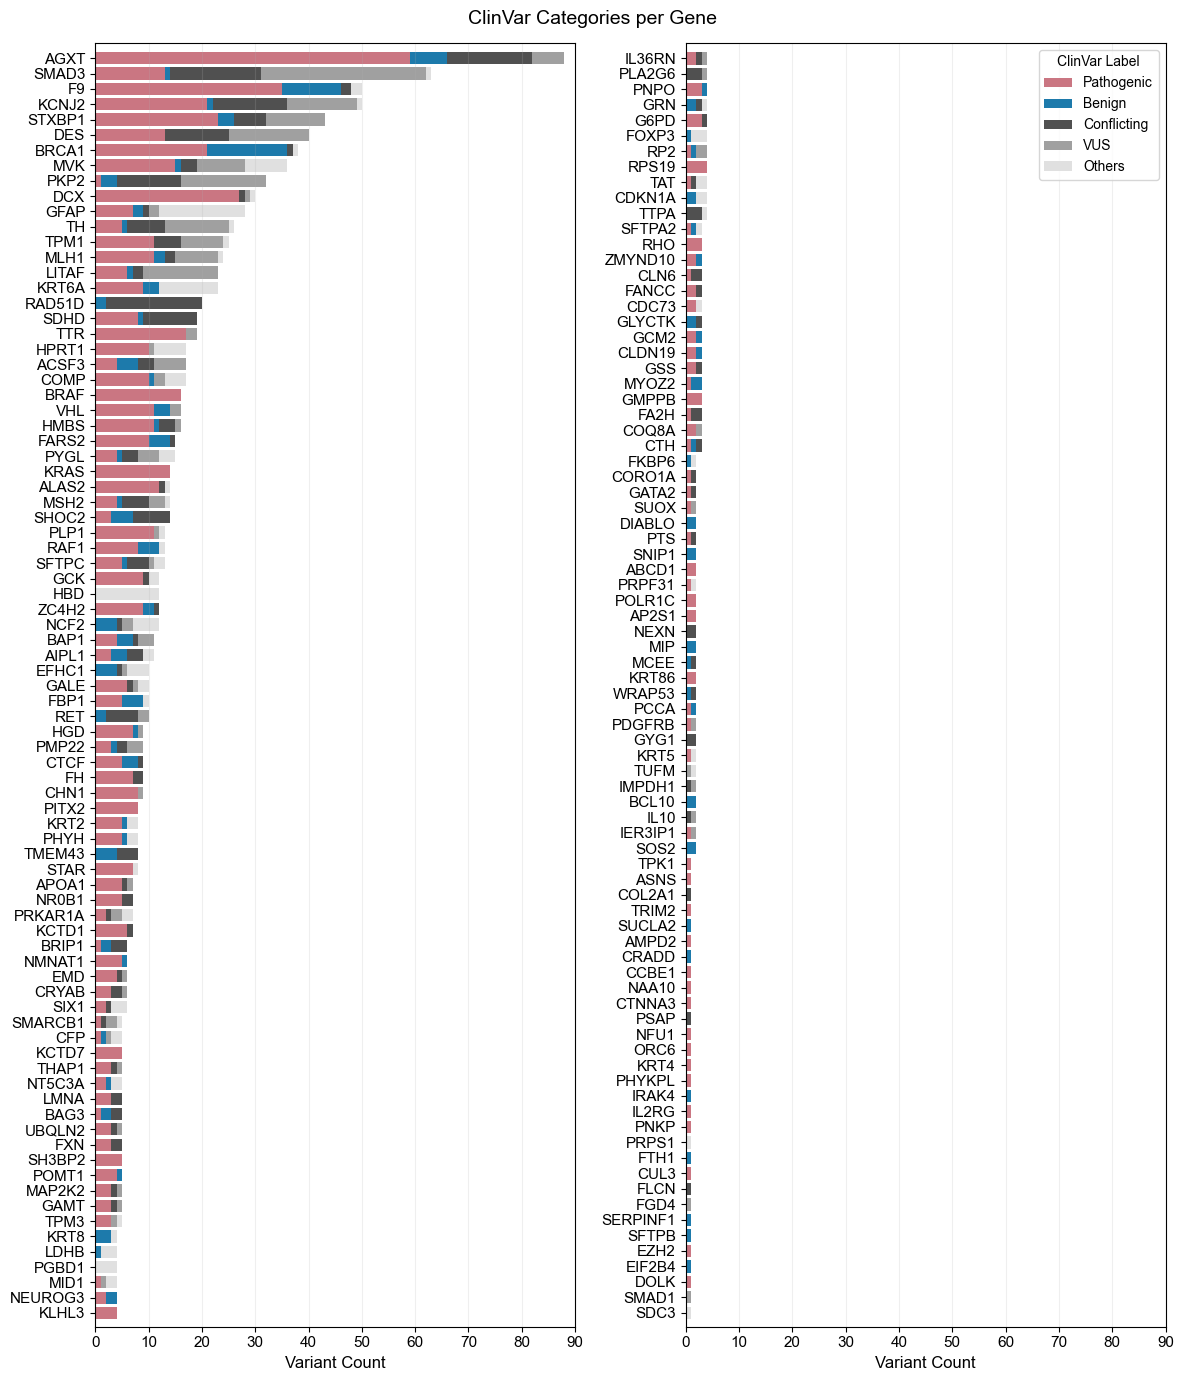

In [29]:
# 2. Count per (gene, category)
df = al_dual_img_ppi_assayed_dedup.to_pandas() ## drop_nulls("clinvar_clnsig_clean").

top_num = int(np.ceil(al_dual_img_ppi_assayed_dedup.unique("symbol").shape[0] / 2))
counts = (
    df.groupby(["symbol", "clinvar_clnsig_clean"])
    .size()
    .reset_index(name="count")
)
# 3. Pivot
pivot = counts.pivot(index="symbol", columns="clinvar_clnsig_clean", values="count").fillna(0)

# Add total count column and sort by it (descending)
pivot["total_count"] = pivot.sum(axis=1)
pivot_top = pivot.sort_values("total_count", ascending=False).head(top_num)
pivot_top = pivot_top.drop(columns=["total_count"])
# category_order = sorted(pivot_top["clinvar_clnsig_clean"].unique())

# # 4. Ensure category order
# for cat in category_order:
#     if cat not in pivot_top.columns:
#         pivot_top[cat] = 0
# pivot_top = pivot_top[category_order]

# 5. Plotting
fig, axes = plt.subplots(1,2, figsize=(12, 14))
# Get Set2 colors
bottom = None
for cat, color in palette_dict["clinvar_clnsig_clean"].items():
    axes[0].barh(pivot_top.index, pivot_top[cat], 
            left=bottom, label=cat, color=color)
    bottom = pivot_top[cat] if bottom is None else bottom + pivot_top[cat]
    
# Axis formatting
axes[0].set_xlabel("Variant Count")
axes[0].set_xlim(None, 90)
axes[0].set_ylim(-1, pivot_top.shape[0] - .1)  # Tighten y-axis to remove top/bottom gaps
# axes[0].set_title(f"ClinVar Categories per Gene (Top {top_num} with Most Variants)", fontsize=14)
axes[0].invert_yaxis()
axes[0].grid(alpha=.2, axis="x")

# ax.legend(title="ClinVar Label", fontsize=9, title_fontsize=10, loc="lower right")
# plt.tight_layout()
# plt.show()

pivot_bot = pivot.sort_values("total_count", ascending=False).iloc[top_num:,].copy()
pivot_bot = pivot_bot.drop(columns=["total_count"])

# 4. Ensure category order
# for cat in category_order:
#     if cat not in pivot_bot.columns:
#         pivot_bot[cat] = 0
# pivot_bot = pivot_bot[category_order]

bottom = None
for cat, color in palette_dict["clinvar_clnsig_clean"].items():
    axes[1].barh(pivot_bot.index, pivot_bot[cat], left=bottom, label=cat, color=color)
    bottom = pivot_bot[cat] if bottom is None else bottom + pivot_bot[cat]
    
# Axis formatting
axes[1].set_xlabel("Variant Count")
axes[1].set_xlim(None, 90)
axes[1].set_ylim(-1, pivot_bot.shape[0] - .1)  # Tighten y-axis to remove top/bottom gaps
# axes[1].set_title(f"ClinVar Categories per Gene ({top_num} After)", fontsize=14)
axes[1].invert_yaxis()
axes[1].legend(title="ClinVar Label", fontsize=10, title_fontsize=10, loc="upper right")
axes[1].grid(alpha=.2, axis="x")
plt.suptitle(f"ClinVar Categories per Gene", fontsize=14, y=.985)
plt.tight_layout()
plt.show()

In [29]:
# # Create pie chart for ClinVar annotation categories
# fig, ax = plt.subplots(1, 1, figsize=(8, 8))

# # Get the category counts from the merged data
# summary_clin_var_counts = alleles_prof_one_assay.group_by("clinvar_clnsig_clean").len() #.sort("clinvar_clnsig_clean")#.sort("len", descending=True)
# summary_clin_var_counts = alleles_prof_one_assay.group_by("clinvar_clnsig_clean").len().to_pandas()
# category_order = ["1_Pathogenic", "2_Benign", "3_Conflicting", "4_VUS", "5_Others"]
# summary_clin_var_counts['clinvar_clnsig_clean'] = pd.Categorical(summary_clin_var_counts['clinvar_clnsig_clean'], categories=category_order, ordered=True)

# # Convert to pandas for easier plotting
# pie_data = summary_clin_var_counts.sort_values('clinvar_clnsig_clean')
# pie_data = pie_data.dropna()  # Remove any null values

# # Calculate percentages
# total_count = pie_data["len"].sum()
# pie_data["percentage"] = (pie_data["len"] / total_count * 100).round(1)

# # Create labels with counts and percentages
# labels = [f"{cat.split('_')[1]}\n({count}, {pct}%)" 
#           for cat, count, pct in zip(pie_data["clinvar_clnsig_clean"], 
#                                    pie_data["len"], 
#                                    pie_data["percentage"])]

# # Use a color palette that matches the boxenplot
# colors = list(palette_dict["clinvar_clnsig_clean"].values())
# # colors[1], colors[3] = colors[3], colors[1]  # Swap colors to match the order in pie chart
# # Create pie chart
# wedges, texts, autotexts = ax.pie(pie_data["len"], 
#                                   labels=labels, 
#                                   colors=colors,
#                                   autopct="",  # We're including percentages in labels
#                                   startangle=90,
#                                   textprops={'fontsize': 12})

# ax.set_title("Distribution of ClinVar Annotation Categories", fontsize=14, fontweight='bold', pad=20)

# # Equal aspect ratio ensures that pie is drawn as a circle
# ax.axis('equal')

# # # Add a legend
# # ax.legend(wedges, [f"{cat} (n={count})" for cat, count in zip(pie_data["clinvar_clnsig_clean"], pie_data["len"])],
# #           title="Categories",
# #           loc="center left",
# #           bbox_to_anchor=(1, 0, 0.5, 1))

# plt.tight_layout()
# plt.show()

# # Print summary statistics
# print("ClinVar Annotation Distribution:")
# print("=" * 40)
# for _, row in pie_data.iterrows():
#     print(f"{row['clinvar_clnsig_clean']}: {row['len']} variants ({row['percentage']}%)")
# print(f"\nTotal variants: {total_count}")

In [60]:
def plot_assay_hit_by_category_perc(df, hit_col, cat_cols, title="", ax=None):
    """
    plot_assay_hit_by_category
    ==========================
    
    Create a stacked horizontal bar chart showing hit rate percentage per category.
    Each bar represents 100% of the category, with the hit portion highlighted.
    
    Parameters
    ----------
    df : polars.DataFrame
        Input table containing at least the columns listed in `cat_cols` and a
        boolean column indicating hits.
    hit_col : str
        Name of the boolean column that flags hits (e.g. `"is_hit"`).
    cat_cols : str or list[str]
        Column(s) that define the categorical grouping(s).  If a single string is
        supplied it is handled automatically.
    title : str, optional
        Title placed above the plot.
    ax : matplotlib.axes.Axes, optional
        Pre-existing axes to draw on.  If None, a new figure and axes are created.
    
    Returns
    -------
    polars.DataFrame
        A tidy frame with one row per category, containing:
            - the grouping key(s)
            - total_counts   : total observations in that category
            - hit_counts     : observations that were hits
            - hit_perc       : hit rate in percent (hit_counts / total_counts * 100)
    """
    # --- compute hit counts and percentages ---
    df_tot_cnt_per_cat = (
        df.group_by(cat_cols)
        .len()
        .rename({"len": "total_counts"})
    )
    df_hit_cnt_per_cat = (
        df.unique("gene_variant")
        .filter(pl.col(hit_col))
        .group_by(cat_cols)
        .len()
        .rename({"len": "hit_counts"})
    )

    cat_col_name = cat_cols if isinstance(cat_cols, str) else cat_cols[-1]
    
    img_hits_perc_df = (
        df_tot_cnt_per_cat.join(
            df_hit_cnt_per_cat,
            on=cat_cols,
            how="left"
        )
        .fill_null(0)
        .with_columns(
            (pl.col("hit_counts") / pl.col("total_counts") * 100).alias("hit_perc")
        )
        .sort(cat_col_name, descending=True)
    )

    # --- plotting ---
    if ax is None:
        _, ax = plt.subplots(1, 1, figsize=(5, img_hits_perc_df.shape[0]))

    plot_df = img_hits_perc_df.to_pandas()
    y_positions = range(len(plot_df))

    # background bars (full 100% - gray)
    ax.barh(y_positions, [100] * len(plot_df), color='#00A3A3', label="Non-hit")
    # hit bars (foreground - red)
    ax.barh(y_positions, plot_df["hit_perc"], color='#E67300', label="Hit")

    # set labels
    ax.set_yticks(y_positions)
    ax.set_yticklabels([f"{cat}\n(n={n})" for cat, n in zip(plot_df[cat_col_name], plot_df["total_counts"])]) ##.split('_')[1]
    ax.set_xlabel("Percentage (%)")
    ax.set_xlim(0, 100)
    ax.set_title(title)
    ax.grid(axis='x', alpha=.2)
    ax.legend(loc='lower right')

    # percentage annotations - positioned at the end of hit bar
    for idx, row in plot_df.iterrows():
        ax.text(
            row["hit_perc"] + 1,
            idx,
            f"{row['hit_perc']:.1f}%",
            va="center",
            ha="left",
            fontweight="bold",
            fontsize=11,
            color="white"
        )
    return img_hits_perc_df


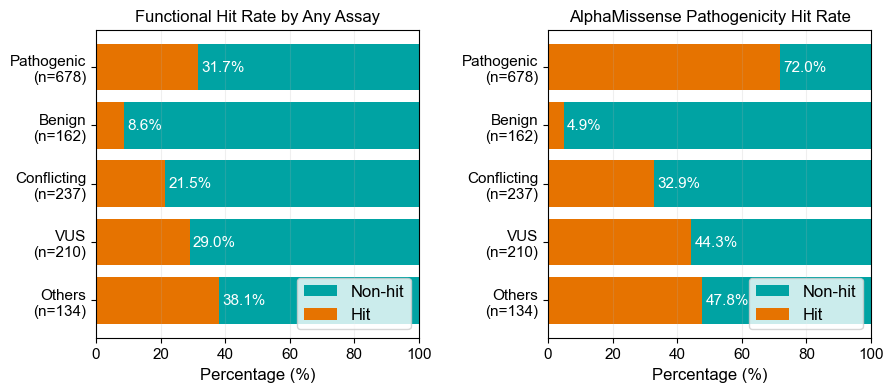

In [ ]:
alleles_prof_one_assay = al_dual_img_ppi_assayed_dedup.with_columns(
    pl.when((pl.col("dualipa_abun_change")=="Y") | (pl.col("imaging_hit")) | (pl.col("ppi_hit")))
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("any_assay_hit"),
    pl.col("gene_variant").alias("gene_allele")
)

fig, axes = plt.subplots(1,2,figsize=(10,4))
df = alleles_prof_one_assay.unique("gene_variant").to_pandas()
df["AlphaMissense_score"] = df["AlphaMissense_score"].replace(".",np.nan).astype(float)
df["AlphaMissense_pred_call"] = df["AlphaMissense_pred"].astype(str).apply(lambda x : True if "P" in x else False)

plot_assay_hit_by_category_perc(alleles_prof_one_assay.with_columns(
        pl.col("clinvar_clnsig_clean")
            .cast(pl.Enum(clinvar_order_dict["original"]))
    ).sort("clinvar_clnsig_clean"), 
    "any_assay_hit", "clinvar_clnsig_clean", 
    f"Functional Hit Rate by Any Assay",
    ax=axes[0]
)
plot_assay_hit_by_category_perc(
    pl.DataFrame(df).with_columns(
        pl.col("clinvar_clnsig_clean")
            .cast(pl.Enum(clinvar_order_dict["original"]))
    ).sort("clinvar_clnsig_clean"), 
    "AlphaMissense_pred_call", 
    "clinvar_clnsig_clean", 
    f"AlphaMissense Pathogenicity Hit Rate", 
    ax=axes[1]
)
plt.subplots_adjust(wspace=0.4)
# plt.savefig("../4_manuscript_figures/variant_hit_rate_per_clinvar.svg",  dpi=400, transparent=True, bbox_inches='tight')
plt.show()

In [63]:
contingency_table = al_dual_img_ppi_assayed_dedup.with_columns(
    pl.when((pl.col("dualipa_abun_change")=="Y") | (pl.col("imaging_hit")) | (pl.col("ppi_hit")))
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("any_assay_hit")
).group_by(
    ["any_assay_hit", 'clinvar_clnsig_clean']
).agg(
    pl.len()
).pivot(
    index="any_assay_hit",
    on='clinvar_clnsig_clean',
    values="len"
).sort(
    "any_assay_hit", descending=True
)
print(
    contingency_table.select(
        (pl.col("Pathogenic").first() / pl.col("Pathogenic").sum()).alias("Pathogenic_hit_rate"),
        (pl.col("Benign").first() / pl.col("Benign").sum()).alias("Benign_hit_rate")
    )
)
table = contingency_table.select(["Pathogenic", "Benign"]).to_numpy()  # Flip so true is first row
odds_ratio, p_value = fisher_exact(table, alternative='two-sided')

print(p_value)

shape: (1, 2)
┌─────────────────────┬─────────────────┐
│ Pathogenic_hit_rate ┆ Benign_hit_rate │
│ ---                 ┆ ---             │
│ f64                 ┆ f64             │
╞═════════════════════╪═════════════════╡
│ 0.317109            ┆ 0.08642         │
└─────────────────────┴─────────────────┘
1.6526778281483728e-10


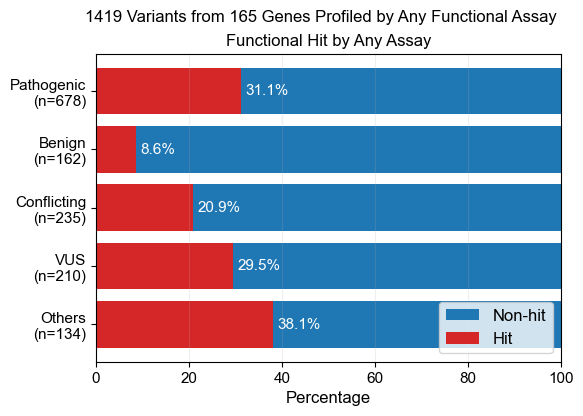

In [31]:
fig, axes = plt.subplots(1,1,figsize=(6,4), sharey=False)
# plot_cat_count_perc(
#     alleles_prof_one_assay.with_columns(
#         pl.col("clinvar_clnsig_clean")
#             .cast(pl.Enum([c for c in clinvar_order_dict["original"] if "Likely" not in c]))
#     ).sort("clinvar_clnsig_clean"),
#     "clinvar_clnsig_clean",
#     title="ClinVar",
#     ax=axes[1],
#     palette=palette_dict["clinvar_clnsig_clean"]
# )
# axes[1].set_title("Genetic Variant ClinVar Distribution")
# axes[1].set_xlabel("Count")
# axes[1].set_ylabel("")
# axes[1].set_yticklabels("")
# axes[1].grid(alpha=.2)

plot_assay_hit_by_category_perc(
    alleles_prof_one_assay.with_columns(
        pl.col("clinvar_clnsig_clean")
            .cast(pl.Enum([c for c in clinvar_order_dict["original"] if "Likely" not in c]))
    ).sort("clinvar_clnsig_clean"), 
    "any_assay_hit", 
    "clinvar_clnsig_clean", 
    f"Functional Hit by Any Assay", 
    ax=axes
)
axes.set_xlabel("Percentage")

plt.suptitle(f"{alleles_prof_one_assay.unique('gene_variant').shape[0]} Variants from {alleles_prof_one_assay.unique('symbol').shape[0]} Genes Profiled by Any Functional Assay", y=.99, fontsize=12)
plt.subplots_adjust(wspace=.05)
plt.show()

### 3.3 Plot hits

In [115]:
# from matplotlib.colors import ListedColormap
# from matplotlib.patches import Patch

# al_dual_img_ppi_intersect = al_dual_img_ppi_assayed_dedup.filter(
#     pl.col("dualipa_score").is_not_null(),
#     pl.col("imaging_score").is_not_null(),
#     pl.col("ppi_score").is_not_null()
# ).unique("gene_variant")

# df = al_dual_img_ppi_intersect.select(
#     pl.col(["symbol", "gene_variant", "dualipa_abun_change", "img_pheno_hit", "ppi_hit", "clinvar_clnsig_clean"])
# ).with_columns(
#     pl.when(pl.col("dualipa_abun_change")=="Y")
#     .then(pl.lit(1))
#     .otherwise(pl.lit(0))
#     .alias("Abundance"),
#     pl.col("img_pheno_hit").cast(pl.Int8).alias("Imaging"),
#     pl.col("ppi_hit").alias("PPI"),
# ).to_pandas()

# # Ensure hit columns are ints
# hit_cols = ['Abundance', 'Imaging', 'PPI']
# df[hit_cols] = df[hit_cols].astype(int)

# # Sort by gene symbol and ClinVar category
# df_sorted = df.sort_values(['symbol', 'clinvar_clnsig_clean'])

# # Create the hit matrix
# matrix = df_sorted.set_index('gene_variant')[hit_cols]

# # Row colors for ClinVar categories
# lut = palette_dict["clinvar_clnsig_clean"]
# row_colors_clinvar = df_sorted['clinvar_clnsig_clean'].map(lut).values

# # Split genes into three groups while keeping alleles together
# unique_genes = df_sorted['symbol'].unique()
# n_genes = len(unique_genes)
# split_point1 = n_genes // 3
# split_point2 = 2 * n_genes // 3

# genes_part1 = unique_genes[:split_point1]
# genes_part2 = unique_genes[split_point1:split_point2]
# genes_part3 = unique_genes[split_point2:]

# # Create three separate datasets
# df_part1 = df_sorted[df_sorted['symbol'].isin(genes_part1)]
# df_part2 = df_sorted[df_sorted['symbol'].isin(genes_part2)]
# df_part3 = df_sorted[df_sorted['symbol'].isin(genes_part3)]

# def create_clustermap_part(df_part, part_name, genes_subset):
#     # Create matrix for this part
#     matrix_part = df_part.set_index('gene_variant')[hit_cols]
    
#     # Row colors for ClinVar categories
#     row_colors_clinvar_part = df_part['clinvar_clnsig_clean'].map(lut).values
    
#     # Row colors for gene symbols (use consistent colors)
#     gene_palette = sns.color_palette("tab20", 20) + sns.color_palette("Set1", n_genes-20)
#     gene_lut = dict(zip(unique_genes, gene_palette))  # Keep all genes for consistent colors
#     row_colors_genes_part = [gene_lut[gene] for gene in df_part['symbol']]
    
#     # Combine row colors
#     row_colors_part = [row_colors_clinvar_part] #row_colors_genes_part
    
#     # Create clustermap
#     g = sns.clustermap(
#         matrix_part,
#         row_cluster=False,
#         col_cluster=False,
#         cmap=custom_cmap,
#         linewidths=0.5,
#         row_colors=row_colors_part,
#         figsize=(4.5,12),
#         colors_ratio=0.1,  # Increase from default 0.03 to make row colors wider
#         cbar_pos=(-0.2, 0.45, 0.05, 0.18),
#         cbar_kws={
#             "ticks": [0, 1],
#             "format": "%d",
#             "format": lambda x, pos: "False" if x == 0 else "True",
#         },
#         dendrogram_ratio=0.01,  # Remove dendrogram space
#         yticklabels=1
#     )
    
#     # Add legend for ClinVar categories
#     handles = [Patch(facecolor=color, label=label) for label, color in lut.items()]
#     g.ax_heatmap.legend(
#         handles=handles,
#         title='ClinVar',
#         bbox_to_anchor=(-1., 0.35),
#         loc='center left',
#         frameon=False,
#         fontsize=10
#     )
#     g.ax_heatmap.tick_params(axis='x', rotation=45)
#     # g.ax_heatmap.set_yticks(range(len(matrix_part)))
#     # g.ax_heatmap.set_yticklabels(matrix_part.index, fontsize=10, va='center')

#     # Change colorbar labels
#     # g.ax_cbar.set_yticklabels(['False', 'True'])
    
#     # plt.suptitle(f'{part_name} (Genes: {", ".join(genes_subset[:5])}{"..." if len(genes_subset) > 5 else ""})', 
#     #              y=1., fontsize=14)
#     plt.show()

# # Create both parts
# print(f"Part 1: {len(genes_part1)} genes, {len(df_part1)} variants")
# create_clustermap_part(df_part1, "Part 1", genes_part1)

# print(f"Part 2: {len(genes_part2)} genes, {len(df_part2)} variants")
# create_clustermap_part(df_part2, "Part 2", genes_part2)

# print(f"Part 2: {len(genes_part2)} genes, {len(df_part2)} variants")
# create_clustermap_part(df_part3, "Part 3", genes_part3)